In [13]:
import numpy as np
import pandas as pd
from pathlib import Path

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Libraries imported successfully!")

NumPy: 2.5.4
Pandas: 3.1.0
Libraries imported successfully!


In [14]:
columns = (
    ['unit', 'cycle']
    + [f'op_setting_{i}' for i in range(1, 4)]
    + [f'sensor_{i}' for i in range(1, 22)]
)

print("Total columns:", len(columns))
print(columns)

Total columns: 26
['unit', 'cycle', 'op_setting_1', 'op_setting_2', 'op_setting_3', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21']


In [15]:
DATA_DIR = Path("../data/raw/CMaps")

train_path = DATA_DIR / "train_FD001.txt"

train_df = pd.read_csv(
    train_path,
    sep=r"\s+",
    header=None,
    names=columns
)

print("Training dataset shape:", train_df.shape)
train_df.head()

Training dataset shape: (20631, 26)


,unit,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [16]:
test_df = pd.read_csv(
    DATA_DIR / "test_FD001.txt",
    sep=r"\s+",
    header=None,
    names=columns
)

rul_df = pd.read_csv(
    DATA_DIR / "RUL_FD001.txt",
    sep=r"\s+",
    header=None,
    names=['RUL']
)

print("Test dataset shape:", test_df.shape)
print("RUL dataset shape:", rul_df.shape)

print("\nNumber of training engines:", train_df['unit'].nunique())
print("Number of test engines:", test_df['unit'].nunique())

Test dataset shape: (13096, 26)
RUL dataset shape: (100, 1)

Number of training engines: 100
Number of test engines: 100


In [17]:
print("TRAINING DATA:", train_df.shape)
print("TEST DATA:", test_df.shape)
print("RUL DATA:", rul_df.shape)

print("\nFIRST 5 TRAINING RECORDS:")
display(train_df.head())

print("\nFIRST 5 TEST RECORDS:")
display(test_df.head())

print("\nFIRST 5 TEST RUL VALUES:")
display(rul_df.head())

TRAINING DATA: (20631, 26)
TEST DATA: (13096, 26)
RUL DATA: (100, 1)

FIRST 5 TRAINING RECORDS:


,unit,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044



FIRST 5 TEST RECORDS:


,unit,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,0.0023,0.0003,100.0,518.67,643.02,1585.29,1398.21,14.62,...,521.72,2388.03,8125.55,8.4052,0.03,392,2388,100.0,38.86,23.3735
1,1,2,-0.0027,-0.0003,100.0,518.67,641.71,1588.45,1395.42,14.62,...,522.16,2388.06,8139.62,8.3803,0.03,393,2388,100.0,39.02,23.3916
2,1,3,0.0003,0.0001,100.0,518.67,642.46,1586.94,1401.34,14.62,...,521.97,2388.03,8130.10,8.4441,0.03,393,2388,100.0,39.08,23.4166
3,1,4,0.0042,0.0000,100.0,518.67,642.44,1584.12,1406.42,14.62,...,521.38,2388.05,8132.90,8.3917,0.03,391,2388,100.0,39.00,23.3737
4,1,5,0.0014,0.0000,100.0,518.67,642.51,1587.19,1401.92,14.62,...,522.15,2388.03,8129.54,8.4031,0.03,390,2388,100.0,38.99,23.4130



FIRST 5 TEST RUL VALUES:


,RUL
0,112
1,98
2,69
3,82
4,91


---
# Exploratory Data Analysis (EDA)

This section conducts systematic exploratory data analysis on the NASA C-MAPSS FD001 dataset across five key investigations:
1. **Dataset Verification:** Checking shapes, engine counts, missing values, duplicates, and column data types.
2. **Engine Lifespan Analysis:** Examining run-to-failure cycle distributions and variability across training units.
3. **Sensor Behavior:** Visualizing telemetry degradation trajectories over operational cycles for key sensors.
4. **Constant and Near-Constant Sensors:** Screening non-informative sensor channels with zero or negligible variance.
5. **Sensor Correlation:** Evaluating inter-sensor dependencies and identifying co-degrading sensor clusters.

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting configuration for academic report plots
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 10
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 11

# Define sensor column list for reuse across EDA tasks
sensor_cols = [f"sensor_{i}" for i in range(1, 22)]
print("Visualization libraries configured. Total sensors tracked:", len(sensor_cols))

Visualization libraries configured. Total sensors tracked: 21


---
## 1. Dataset Verification

Before proceeding with modeling, we verify dataset integrity:
- Confirming matrix shapes for `train_df`, `test_df`, and `rul_df`.
- Counting unique engine units in training and test splits.
- Checking for any missing (`NaN` / null) values or duplicate rows.
- Verifying feature data types.

In [19]:
print("=" * 65)
print("1.1 DATASET SHAPES & UNIQUE ENGINES")
print("=" * 65)
print(f"train_df shape : {train_df.shape}  ({train_df.shape[0]:,} rows, {train_df.shape[1]} columns)")
print(f"test_df shape  : {test_df.shape}  ({test_df.shape[0]:,} rows, {test_df.shape[1]} columns)")
print(f"rul_df shape   : {rul_df.shape}    ({rul_df.shape[0]:,} ground truth RUL values)")
print("-" * 65)
print(f"Unique training engines (units) : {train_df['unit'].nunique()}")
print(f"Unique test engines (units)     : {test_df['unit'].nunique()}")
print("=" * 65)

print("\n" + "=" * 65)
print("1.2 DATA INTEGRITY: MISSING VALUES & DUPLICATE ROWS")
print("=" * 65)
print(f"Missing values in train_df : {train_df.isnull().sum().sum()}")
print(f"Missing values in test_df  : {test_df.isnull().sum().sum()}")
print(f"Missing values in rul_df   : {rul_df.isnull().sum().sum()}")
print("-" * 65)
print(f"Duplicate rows in train_df : {train_df.duplicated().sum()}")
print(f"Duplicate rows in test_df  : {test_df.duplicated().sum()}")
print(f"Duplicate rows in rul_df   : {rul_df.duplicated().sum()}")
print("=" * 65)

print("\n" + "=" * 65)
print("1.3 DATA TYPES BREAKDOWN")
print("=" * 65)
print("Data type distribution across train_df columns:")
print(train_df.dtypes.value_counts())
print("\nSummary table of column types:")
dtypes_df = pd.DataFrame({
    "train_dtype": train_df.dtypes,
    "test_dtype": test_df.dtypes,
    "sample_value": train_df.iloc[0]
})
display(dtypes_df.T)

1.1 DATASET SHAPES & UNIQUE ENGINES
train_df shape : (20631, 26)  (20,631 rows, 26 columns)
test_df shape  : (13096, 26)  (13,096 rows, 26 columns)
rul_df shape   : (100, 1)    (100 ground truth RUL values)
-----------------------------------------------------------------
Unique training engines (units) : 100
Unique test engines (units)     : 100

1.2 DATA INTEGRITY: MISSING VALUES & DUPLICATE ROWS
Missing values in train_df : 0
Missing values in test_df  : 0
Missing values in rul_df   : 0
-----------------------------------------------------------------
Duplicate rows in train_df : 0
Duplicate rows in test_df  : 0
Duplicate rows in rul_df   : 29

1.3 DATA TYPES BREAKDOWN
Data type distribution across train_df columns:
float64    22
int64       4
Name: count, dtype: int64

Summary table of column types:


,unit,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
train_dtype,int64,int64,float64,float64,float64,float64,float64,float64,float64,float64,...,float64,float64,float64,float64,float64,int64,int64,float64,float64,float64
test_dtype,int64,int64,float64,float64,float64,float64,float64,float64,float64,float64,...,float64,float64,float64,float64,float64,int64,int64,float64,float64,float64
sample_value,1.0,1.0,-0.0007,-0.0004,100.0,518.67,641.82,1589.7,1400.6,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392.0,2388.0,100.0,39.06,23.419


### Observations: Dataset Verification
- **Completeness:** Zero missing values (`NaN`) exist across `train_df`, `test_df`, and `rul_df`.
- **Row Uniqueness:** No duplicate rows were found in either `train_df` or `test_df`. (The 29 duplicate values in `rul_df` represent distinct engines that happen to share identical remaining life cycles at the end of their test recordings, which is expected).
- **Fleet Allocation:** 100 training engines (run to system failure) and 100 test engines (sensor recordings cut off before failure) with 100 corresponding ground truth RUL values.
- **Data Types:** Identifiers (`unit`, `cycle`) are stored as integers (`int64`), while operational settings and sensor measurements are numerical continuous floats (`float64`).

---
## 2. Engine Lifespan Analysis

In the training split, engines are monitored continuously from healthy baseline operation until complete failure. The maximum operating cycle recorded for each training unit represents its **total operational lifespan (time-to-failure)**.

Here, we compute descriptive statistics and visualize the lifespan distribution.

In [20]:
# Calculate maximum cycle (lifespan) for each training engine
engine_lifespans = train_df.groupby("unit")["cycle"].max().rename("max_cycles")

# Compute descriptive statistics
lifespan_stats = engine_lifespans.describe()

print("=" * 65)
print("ENGINE LIFESPAN DESCRIPTIVE STATISTICS (TRAINING FLEET)")
print("=" * 65)
print(lifespan_stats.to_string())
print("-" * 65)
print(f"Shortest Engine Lifespan : Unit {engine_lifespans.idxmin()} ({engine_lifespans.min()} cycles)")
print(f"Longest Engine Lifespan  : Unit {engine_lifespans.idxmax()} ({engine_lifespans.max()} cycles)")
print(f"Mean Lifespan            : {engine_lifespans.mean():.2f} cycles")
print(f"Median (50%) Lifespan    : {engine_lifespans.median():.2f} cycles")
print(f"Standard Deviation       : {engine_lifespans.std():.2f} cycles")
print(f"Interquartile Range (IQR): {engine_lifespans.quantile(0.75) - engine_lifespans.quantile(0.25):.2f} cycles")
print("=" * 65)

ENGINE LIFESPAN DESCRIPTIVE STATISTICS (TRAINING FLEET)
count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
-----------------------------------------------------------------
Shortest Engine Lifespan : Unit 39 (128 cycles)
Longest Engine Lifespan  : Unit 69 (362 cycles)
Mean Lifespan            : 206.31 cycles
Median (50%) Lifespan    : 199.00 cycles
Standard Deviation       : 46.34 cycles
Interquartile Range (IQR): 52.25 cycles


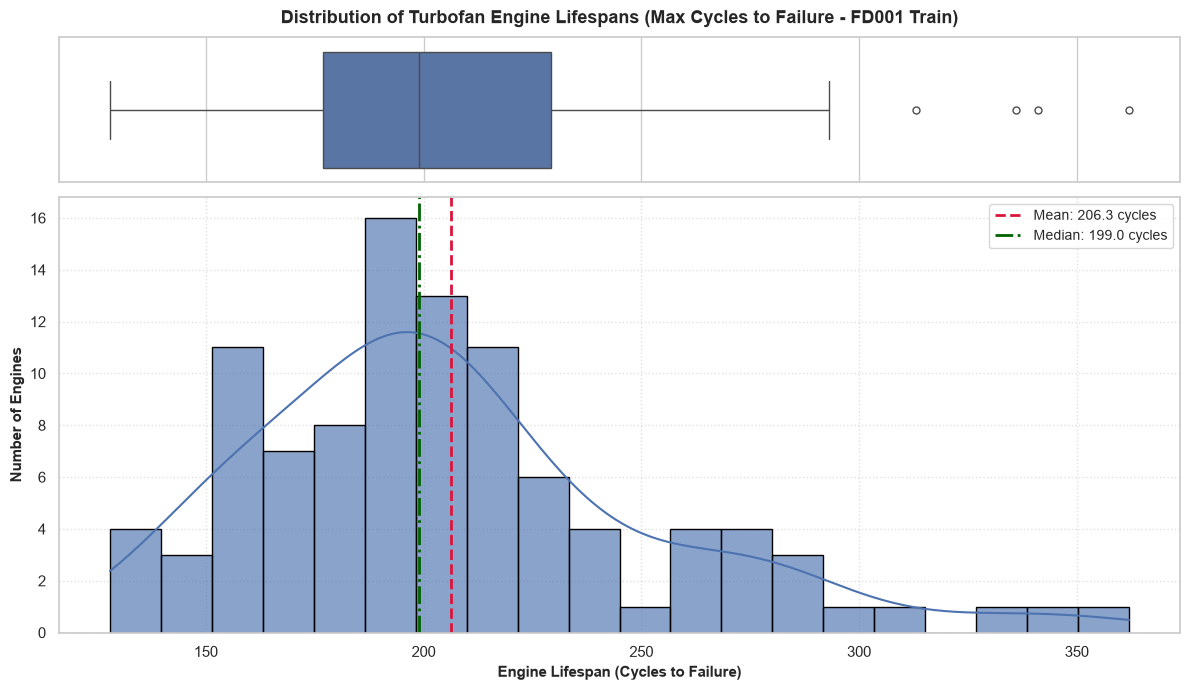

In [21]:
fig, (ax_box, ax_hist) = plt.subplots(
    2, 1, figsize=(12, 7), gridspec_kw={"height_ratios": [0.25, 0.75]}, sharex=True
)

# Boxplot
sns.boxplot(x=engine_lifespans, ax=ax_box, color="#4C72B0", fliersize=5)
ax_box.set(xlabel="")
ax_box.set_title(
    "Distribution of Turbofan Engine Lifespans (Max Cycles to Failure - FD001 Train)",
    fontsize=13, fontweight="bold", pad=10
)

# Histogram + KDE
sns.histplot(
    engine_lifespans,
    bins=20,
    kde=True,
    ax=ax_hist,
    color="#4C72B0",
    edgecolor="black",
    alpha=0.65
)

# Reference lines
mean_life = engine_lifespans.mean()
median_life = engine_lifespans.median()

ax_hist.axvline(
    mean_life, color="crimson", linestyle="--", linewidth=2,
    label=f"Mean: {mean_life:.1f} cycles"
)
ax_hist.axvline(
    median_life, color="darkgreen", linestyle="-.", linewidth=2,
    label=f"Median: {median_life:.1f} cycles"
)

ax_hist.set_xlabel("Engine Lifespan (Cycles to Failure)", fontsize=11, fontweight="bold")
ax_hist.set_ylabel("Number of Engines", fontsize=11, fontweight="bold")
ax_hist.legend(loc="upper right", frameon=True, fontsize=10)
ax_hist.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

### Observations: Engine Lifespan Analysis
- **Wide Lifespan Range:** Engine lifespans vary considerably from **128 cycles** (Unit 39) up to **362 cycles** (Unit 69) — a span of 234 cycles (nearly a 3-fold difference).
- **Central Tendency:** The mean lifespan is **206.31 cycles** with a standard deviation of **46.34 cycles**, closely matching the median of **199.00 cycles**.
- **Distribution Profile:** The histogram shows a unimodal distribution with slight positive skewness, with 50% of the fleet failing between 177 and 229 cycles (IQR = 52.25 cycles).
- **Maintenance Implication:** Because individual engines exhibit varying rates of initial wear and tolerance, fixed-schedule maintenance would either service engines prematurely or risk in-flight failures. Predictive telemetry-driven maintenance is essential.

---
## 3. Sensor Behavior Analysis

We examine operating-cycle trends for six key sensors that capture thermal, pressure, and aerodynamic degradation in the High-Pressure Compressor (HPC):
- **`sensor_2`**: Total temperature at LPC outlet (°R)
- **`sensor_3`**: Total temperature at HPC outlet (°R)
- **`sensor_4`**: Total temperature at LPT outlet (°R)
- **`sensor_7`**: Total pressure at HPC outlet (psia)
- **`sensor_11`**: Static pressure at HPC outlet (psia)
- **`sensor_15`**: Bypass Ratio (BPR)

To maintain chart readability, trends are plotted across a representative selection of five engines: **Units 1, 2, 3, 4, and 5**.

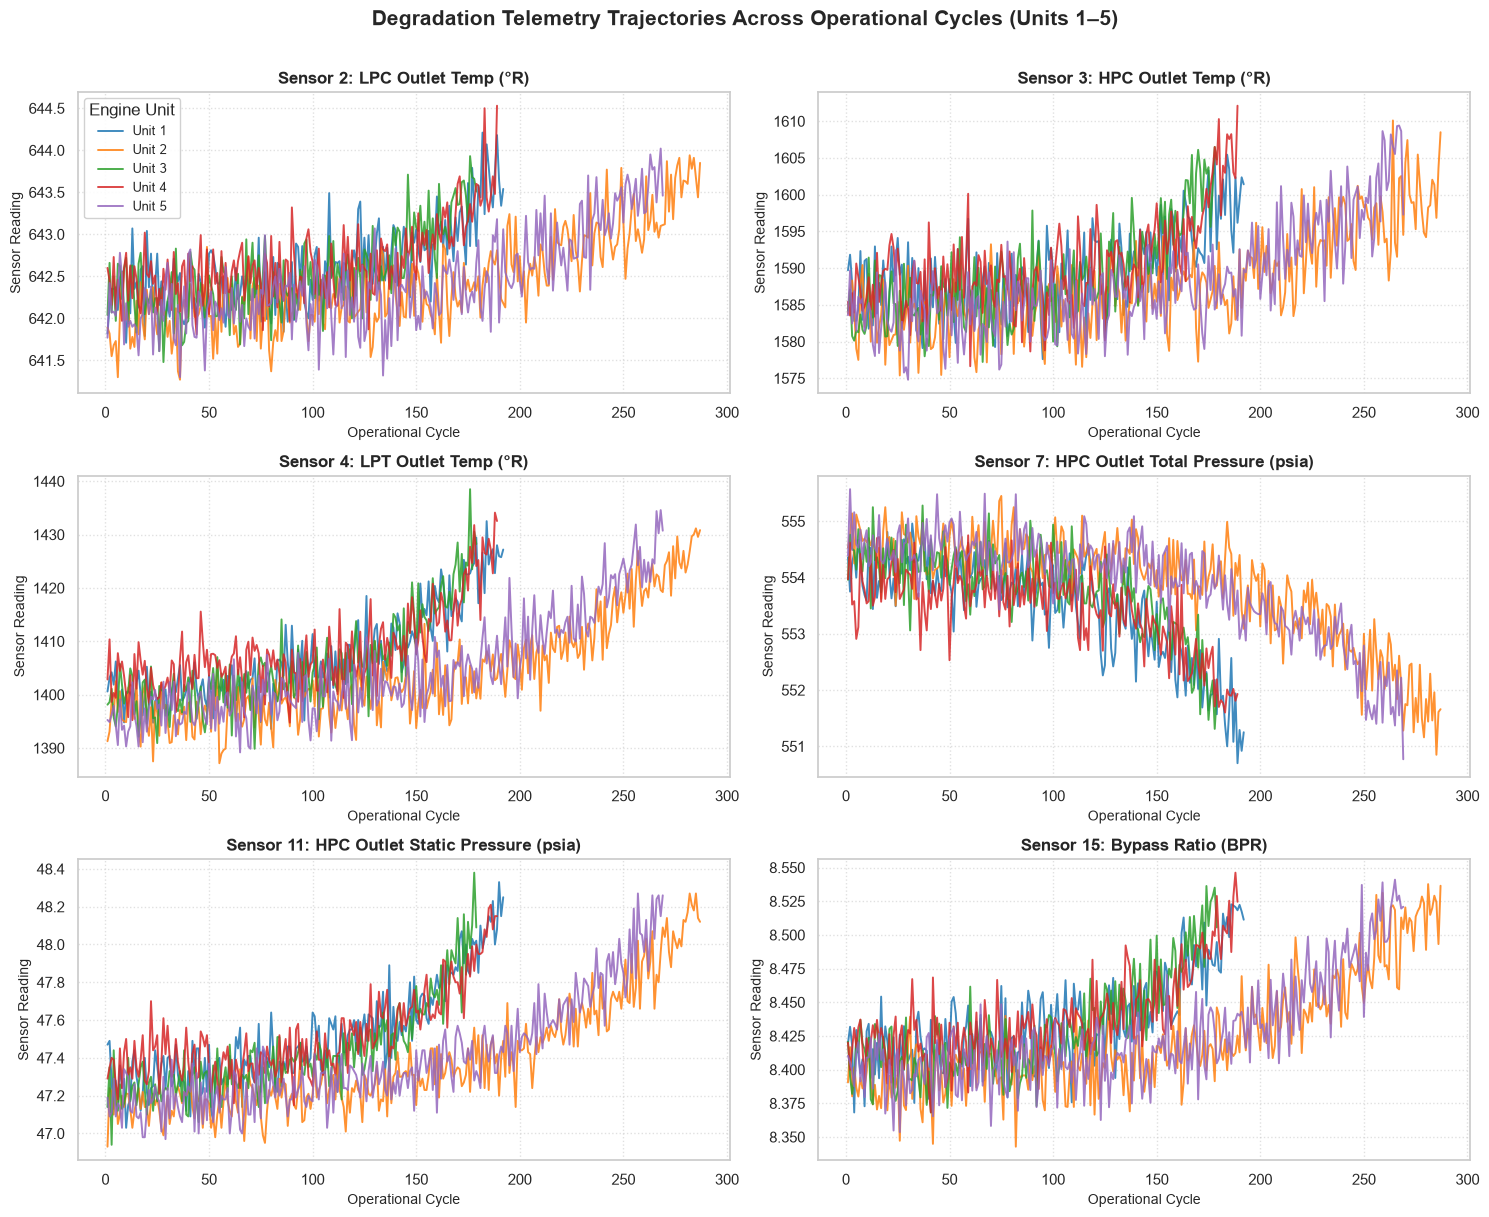

In [22]:
selected_sensors = {
    "sensor_2": "Sensor 2: LPC Outlet Temp (°R)",
    "sensor_3": "Sensor 3: HPC Outlet Temp (°R)",
    "sensor_4": "Sensor 4: LPT Outlet Temp (°R)",
    "sensor_7": "Sensor 7: HPC Outlet Total Pressure (psia)",
    "sensor_11": "Sensor 11: HPC Outlet Static Pressure (psia)",
    "sensor_15": "Sensor 15: Bypass Ratio (BPR)"
}

sample_units = [1, 2, 3, 4, 5]
palette = sns.color_palette("tab10", len(sample_units))

fig, axes = plt.subplots(3, 2, figsize=(15, 12), sharex=False)
axes = axes.flatten()

for idx, (sensor, label) in enumerate(selected_sensors.items()):
    ax = axes[idx]
    for unit, color in zip(sample_units, palette):
        unit_data = train_df[train_df["unit"] == unit]
        ax.plot(
            unit_data["cycle"],
            unit_data[sensor],
            label=f"Unit {unit}",
            color=color,
            alpha=0.85,
            linewidth=1.4
        )
    
    ax.set_title(label, fontsize=12, fontweight="bold")
    ax.set_xlabel("Operational Cycle", fontsize=10)
    ax.set_ylabel("Sensor Reading", fontsize=10)
    ax.grid(True, linestyle=":", alpha=0.6)
    
    if idx == 0:
        ax.legend(title="Engine Unit", loc="upper left", fontsize=9, framealpha=0.9)

plt.suptitle(
    "Degradation Telemetry Trajectories Across Operational Cycles (Units 1–5)",
    fontsize=15, fontweight="bold", y=1.01
)
plt.tight_layout()
plt.show()

### Physical Interpretation of Sensor Trends
1. **Temperature Escalation (`sensor_2`, `sensor_3`, `sensor_4`):**
   - *Trend:* Monotonic upward drift as operational cycles advance toward failure.
   - *Cause:* As compressor blades erode and aerodynamic clearances widen, compression efficiency declines. To deliver required thrust, the engine control system increases fuel consumption, generating higher operating temperatures across compressor and turbine stages.
2. **Total Pressure Drop (`sensor_7`):**
   - *Trend:* Persistent downward drift over the engine's lifecycle.
   - *Cause:* HPC deterioration impedes effective air compression, causing a direct drop in total discharge pressure before combustion.
3. **Static Pressure Rise (`sensor_11`):**
   - *Trend:* Consistent upward drift.
   - *Cause:* Boundary layer separation, blade roughness, and flow blockage increase static resistance within the compressor casing.
4. **Bypass Ratio Expansion (`sensor_15`):**
   - *Trend:* Steady upward drift.
   - *Cause:* Increased core flow resistance causes a higher proportion of intake airflow to route around the core through the bypass duct.
5. **Two-Stage Degradation Profile:**
   - *Phase 1 (Healthy / Flat):* During initial cycles (~0 to 80-100 cycles), sensor values hover around a steady-state baseline with random noise and no discernible drift.
   - *Phase 2 (Accelerated Wear):* Once fault inception occurs, sensor trajectories drift monotonically toward catastrophic failure.

---
## 4. Constant and Near-Constant Sensors

In telemetry-based predictive maintenance, sensor channels that exhibit zero or negligible variance carry no useful degradation signal and add unneeded dimensionality.

### Screening Criteria:
1. **Constant Sensors:** Standard deviation is exactly or numerically zero ($\sigma \approx 0$) and number of unique values is 1 ($\text{nunique} = 1$).
2. **Near-Constant Sensors:** Standard deviation is extremely low ($\sigma < 0.01$), number of unique values is $\le 2$, and the dominant value accounts for $> 95\%$ of all observations.

*(Note: In accordance with project rules, no columns are dropped at this stage).*

In [23]:
# Compute standard deviation, variance, unique count, and dynamic range for each sensor
sensor_variability = pd.DataFrame({
    "std": train_df[sensor_cols].std(),
    "variance": train_df[sensor_cols].var(),
    "nunique": train_df[sensor_cols].nunique(),
    "min": train_df[sensor_cols].min(),
    "max": train_df[sensor_cols].max()
})
sensor_variability["range"] = sensor_variability["max"] - sensor_variability["min"]

# Identify constant sensors (std == 0 or nunique == 1)
constant_mask = (sensor_variability["nunique"] == 1) | (sensor_variability["std"] < 1e-10)
constant_sensors = sensor_variability[constant_mask].index.tolist()

# Identify near-constant sensors (std < 0.01 and nunique <= 2, excluding constant ones)
near_constant_mask = (~constant_mask) & (sensor_variability["std"] < 0.01) & (sensor_variability["nunique"] <= 2)
near_constant_sensors = sensor_variability[near_constant_mask].index.tolist()

# Informative / varying sensors
informative_sensors = [s for s in sensor_cols if s not in constant_sensors and s not in near_constant_sensors]

print("=" * 70)
print("SENSOR VARIABILITY SUMMARY (TRAINING DATA)")
print("=" * 70)
display(sensor_variability.round(6))
print("-" * 70)
print(f"Constant Sensors ({len(constant_sensors)}): {constant_sensors}")
for s in constant_sensors:
    val = train_df[s].iloc[0]
    print(f"  • {s:10}: fixed value = {val}, std = {sensor_variability.loc[s, 'std']:.2e}, nunique = {sensor_variability.loc[s, 'nunique']}")

print(f"\nNear-Constant Sensors ({len(near_constant_sensors)}): {near_constant_sensors}")
for s in near_constant_sensors:
    val_counts = train_df[s].value_counts(normalize=True).to_dict()
    val_counts_str = ', '.join([f'{k}: {v*100:.2f}%' for k, v in val_counts.items()])
    print(f"  • {s:10}: std = {sensor_variability.loc[s, 'std']:.6f}, nunique = {sensor_variability.loc[s, 'nunique']} ({val_counts_str})")

print(f"\nInformative / Varying Sensors ({len(informative_sensors)}): {len(informative_sensors)} sensors")
print(informative_sensors)
print("=" * 70)

SENSOR VARIABILITY SUMMARY (TRAINING DATA)


,std,variance,nunique,min,max,range
sensor_1,0.000000,0.000000,1,518.6700,518.6700,0.0000
sensor_2,0.500053,0.250053,310,641.2100,644.5300,3.3200
sensor_3,6.131150,37.590994,3012,1571.0400,1616.9100,45.8700
sensor_4,9.000605,81.010886,4051,1382.2500,1441.4900,59.2400
sensor_5,0.000000,0.000000,1,14.6200,14.6200,0.0000
sensor_6,0.001389,0.000002,2,21.6000,21.6100,0.0100
sensor_7,0.885092,0.783388,513,549.8500,556.0600,6.2100
sensor_8,0.070985,0.005039,53,2387.9000,2388.5600,0.6600
sensor_9,22.082880,487.653568,6403,9021.7300,9244.5900,222.8600
sensor_10,0.000000,0.000000,1,1.3000,1.3000,0.0000


----------------------------------------------------------------------
Constant Sensors (6): ['sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
  • sensor_1  : fixed value = 518.67, std = 0.00e+00, nunique = 1
  • sensor_5  : fixed value = 14.62, std = 5.33e-15, nunique = 1
  • sensor_10 : fixed value = 1.3, std = 0.00e+00, nunique = 1
  • sensor_16 : fixed value = 0.03, std = 3.47e-18, nunique = 1
  • sensor_18 : fixed value = 2388, std = 0.00e+00, nunique = 1
  • sensor_19 : fixed value = 100.0, std = 0.00e+00, nunique = 1

Near-Constant Sensors (1): ['sensor_6']
  • sensor_6  : std = 0.001389, nunique = 2 (21.61: 98.03%, 21.6: 1.97%)

Informative / Varying Sensors (14): 14 sensors
['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


### Observations: Constant and Near-Constant Sensors
- **6 Strictly Constant Sensors:**
  - `sensor_1` (Fan inlet temperature = 518.67 °R, $\sigma = 0.0$)
  - `sensor_5` (LPC inlet temperature = 14.62 °R, $\sigma \approx 0.0$)
  - `sensor_10` (Bypass duct pressure = 1.30 psia, $\sigma = 0.0$)
  - `sensor_16` (Bypass ratio setting = 0.03, $\sigma \approx 0.0$)
  - `sensor_18` (Demanded fan speed = 2388.0 rpm, $\sigma = 0.0$)
  - `sensor_19` (Demanded corrected fan speed = 100.0 rpm, $\sigma = 0.0$)
  *These sensors reflect fixed sea-level ambient conditions and constant controller demand setpoints in FD001.*
- **1 Near-Constant Sensor:**
  - `sensor_6` (HPC inlet total pressure): Takes only 2 discrete values (21.60 and 21.61) with 98.03% of values at 21.61 ($\sigma \approx 0.00139$, variance $\approx 1.93 \times 10^{-6}$).
- **Informative Sensors:** The remaining 14 sensors (`sensor_2, 3, 4, 7, 8, 9, 11, 12, 13, 14, 15, 17, 20, 21`) contain meaningful variance and capture engine degradation.

---
## 5. Sensor Correlation Analysis

To uncover redundancy and co-varying degradation patterns among telemetry channels, we construct a Pearson correlation matrix for the active (varying) sensor channels.

Constant sensors ($\sigma = 0$) are excluded from the heatmap as their Pearson correlation coefficients are mathematically undefined ($\frac{0}{0} = \text{NaN}$).

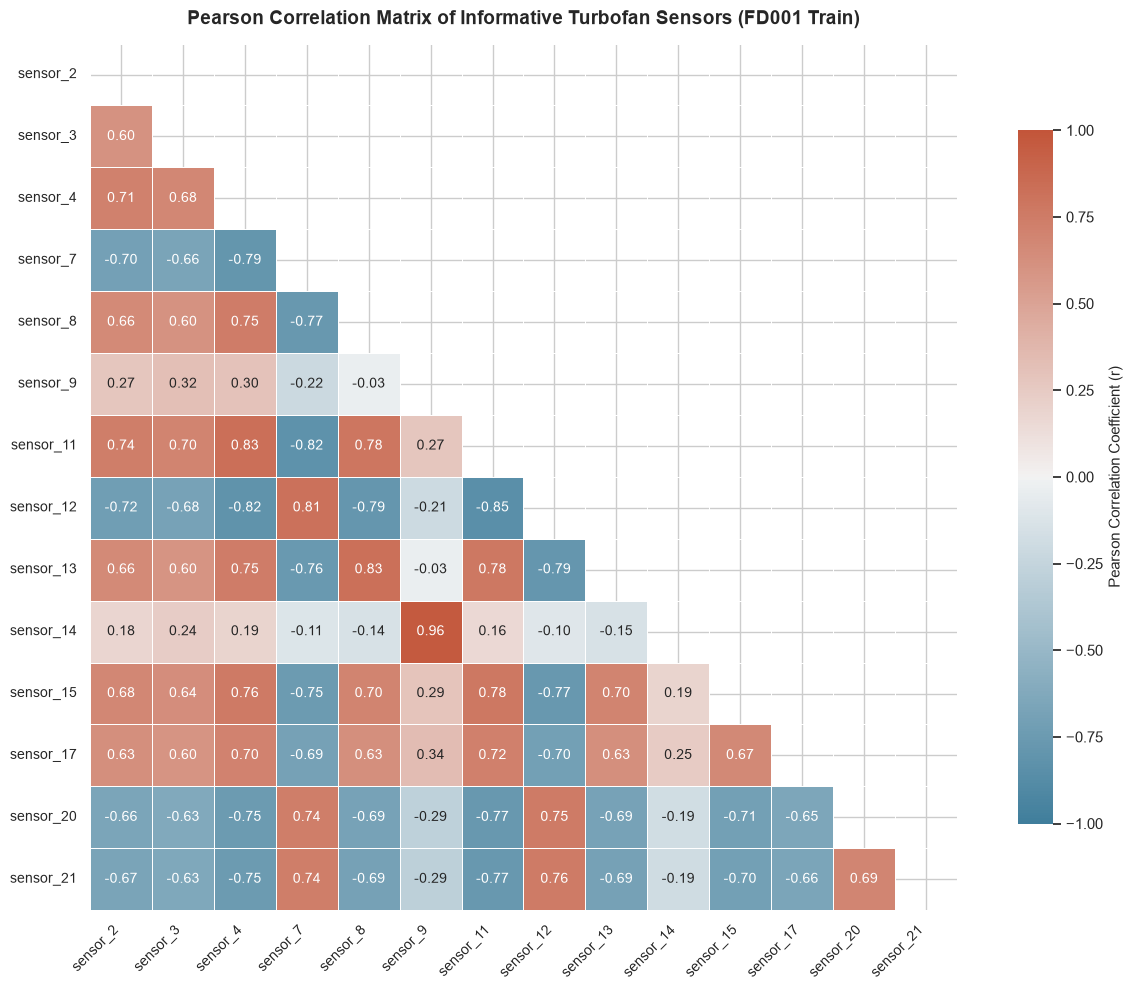

STRONGLY CORRELATED SENSOR PAIRS (|r| >= 0.80)
sensor_9   <---> sensor_14  : r = +0.9632
sensor_11  <---> sensor_12  : r = -0.8469
sensor_4   <---> sensor_11  : r = +0.8301
sensor_8   <---> sensor_13  : r = +0.8261
sensor_7   <---> sensor_11  : r = -0.8228
sensor_4   <---> sensor_12  : r = -0.8156
sensor_7   <---> sensor_12  : r = +0.8127


In [24]:
# Compute correlation matrix for the 14 informative/varying sensors
corr_matrix = train_df[informative_sensors].corr()

# Plot heatmap
plt.figure(figsize=(13, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool)) # Upper triangle mask for readability

cmap = sns.diverging_palette(230, 20, as_cmap=True)

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap=cmap,
    vmin=-1.0,
    vmax=1.0,
    center=0,
    square=True,
    linewidths=0.6,
    cbar_kws={"shrink": 0.8, "label": "Pearson Correlation Coefficient (r)"}
)

plt.title(
    "Pearson Correlation Matrix of Informative Turbofan Sensors (FD001 Train)",
    fontsize=14, fontweight="bold", pad=14
)
plt.xticks(rotation=45, ha="right", fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()
plt.show()

# Identify and display top correlated pairs (|r| >= 0.80)
high_corr_pairs = []
for i in range(len(informative_sensors)):
    for j in range(i + 1, len(informative_sensors)):
        s1 = informative_sensors[i]
        s2 = informative_sensors[j]
        r = corr_matrix.loc[s1, s2]
        if abs(r) >= 0.80:
            high_corr_pairs.append((s1, s2, r))

high_corr_pairs.sort(key=lambda x: abs(x[2]), reverse=True)

print("=" * 65)
print("STRONGLY CORRELATED SENSOR PAIRS (|r| >= 0.80)")
print("=" * 65)
for s1, s2, r in high_corr_pairs:
    print(f"{s1:10} <---> {s2:10} : r = {r:+.4f}")
print("=" * 65)

### Observations: Highly Correlated Sensor Groups
1. **Physical and Corrected Core Speeds (`sensor_9` & `sensor_14`):**
   - *Correlation:* $r = +0.9632$ (near-perfect linear correlation).
   - *Physical Explanation:* `sensor_9` measures physical core speed while `sensor_14` measures corrected core speed. Both reflect the rotational dynamics of the high-pressure spool and co-vary almost identically.
2. **Physical and Corrected Fan Speeds (`sensor_8` & `sensor_13`):**
   - *Correlation:* $r = +0.8261$.
   - *Physical Explanation:* Both sensors monitor low-pressure spool rotational speeds, creating strong operational collinearity.
3. **Thermal and Static Pressure Degradation Cluster:**
   - `sensor_4` (LPT outlet temp) and `sensor_11` (HPC static pressure): $r = +0.8301$.
   - As HPC efficiency declines, both turbine exhaust temperature and compressor static pressure rise concurrently.
4. **Inverse Thermodynamic Degradation Relationship:**
   - `sensor_11` (HPC static pressure) vs. `sensor_12` (fan bypass pressure): $r = -0.8469$.
   - `sensor_7` (HPC total pressure) vs. `sensor_11` (HPC static pressure): $r = -0.8228$.
   - `sensor_4` (LPT outlet temp) vs. `sensor_12` (fan bypass pressure): $r = -0.8156$.
   - `sensor_7` (HPC total pressure) vs. `sensor_12` (fan bypass pressure): $r = +0.8127$.
   - As degradation progresses, total pressure drops while temperatures and static pressures increase, yielding high negative correlations between these opposing clusters.